# Cognifyz Technologies - Data Science Internship
## Level 1 Tasks: Data Exploration, Descriptive Analysis & Geospatial Analysis
**Intern Name:** Yash Devidas Chaudhari  
**Role:** Data Science Intern  
**Company:** Cognifyz Technologies (Cognifyz IT Solutions Pvt. Ltd.)  
**Dataset:** Restaurant Dataset (`Dataset .csv`)  

---
### Table of Contents
1. **Task 1: Data Exploration and Preprocessing**
   - Dataset exploration, dimensions, and schema.
   - Missing value detection and handling.
   - Data type inspection and conversion.
   - Target variable (`Aggregate rating`) distribution and class imbalance analysis.
2. **Task 2: Descriptive Analysis**
   - Statistical measures for numerical columns.
   - Distribution of categorical variables (`Country Code`, `City`, `Cuisines`).
   - Identifying top cuisines and cities with the highest restaurant presence.
3. **Task 3: Geospatial Analysis**
   - Visualizing geographic coordinates on map.
   - Restaurant density across cities and countries.
   - Correlation between restaurant location (coordinates/city) and rating.
---

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import folium
from folium.plugins import MarkerCluster
from scipy import stats
import os
import warnings

warnings.filterwarnings('ignore')

# Set plotting styles
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

# Ensure visualizations folder exists
os.makedirs('visualizations', exist_ok=True)
print("Libraries imported successfully and environment configured!")

Libraries imported successfully and environment configured!


In [2]:
# Load the dataset
df = pd.read_csv('Dataset .csv')

print(f"Dataset Loaded Successfully!")
print(f"Total Rows: {df.shape[0]:,}")
print(f"Total Columns: {df.shape[1]}")
df.head(3)

Dataset Loaded Successfully!
Total Rows: 9,551
Total Columns: 21


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270


---
## Task 1: Data Exploration and Preprocessing

### 1.1 Dataset Exploration & Information
Let's inspect column names, non-null counts, and data types.

In [3]:
# Dataset schema and concise summary
print("--- Column Information & Data Types ---")
df.info()

--- Column Information & Data Types ---
<class 'pandas.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         9551 non-null   int64  
 1   Restaurant Name       9551 non-null   str    
 2   Country Code          9551 non-null   int64  
 3   City                  9551 non-null   str    
 4   Address               9551 non-null   str    
 5   Locality              9551 non-null   str    
 6   Locality Verbose      9551 non-null   str    
 7   Longitude             9551 non-null   float64
 8   Latitude              9551 non-null   float64
 9   Cuisines              9542 non-null   str    
 10  Average Cost for two  9551 non-null   int64  
 11  Currency              9551 non-null   str    
 12  Has Table booking     9551 non-null   str    
 13  Has Online delivery   9551 non-null   str    
 14  Is delivering now     9551 non-null   str  

### 1.2 Missing Value Detection and Handling
We check for missing (null) values in every column and decide on an optimal treatment strategy.

In [4]:
null_counts = df.isnull().sum()
null_percent = (null_counts / len(df)) * 100

missing_summary = pd.DataFrame({
    'Missing Count': null_counts,
    'Percentage (%)': null_percent
})

print("Columns with Missing Values:")
display(missing_summary[missing_summary['Missing Count'] > 0])

# Handling missing values in 'Cuisines':
# Since only 9 rows (0.09%) are missing, we impute them with 'Unknown' so no records are lost.
df['Cuisines'] = df['Cuisines'].fillna('Unknown')
print(f"Missing values in 'Cuisines' after imputation: {df['Cuisines'].isnull().sum()}")

Columns with Missing Values:


,Missing Count,Percentage (%)
Cuisines,9,0.094231


Missing values in 'Cuisines' after imputation: 0


### 1.3 Data Type Inspection and Cleaning
We verify data types and trim leading/trailing whitespaces from text columns.

In [5]:
# Strip any trailing/leading whitespaces from object/string columns
string_cols = df.select_dtypes(include='object').columns
for col in string_cols:
    df[col] = df[col].astype(str).str.strip()

print("String columns cleaned and verified:")
print(list(string_cols))

String columns cleaned and verified:
['Restaurant Name', 'City', 'Address', 'Locality', 'Locality Verbose', 'Cuisines', 'Currency', 'Has Table booking', 'Has Online delivery', 'Is delivering now', 'Switch to order menu', 'Rating color', 'Rating text']


### 1.4 Target Variable (`Aggregate rating`) Distribution & Class Imbalances
The target variable is `Aggregate rating`. Let's analyze its descriptive statistics, skewness, and assess if any class imbalance or data anomaly exists.

--- Aggregate Rating Statistics ---
count    9551.000000
mean        2.666370
std         1.516378
min         0.000000
25%         2.500000
50%         3.200000
75%         3.700000
max         4.900000
Name: Aggregate rating, dtype: float64

Zero Ratings Count (Unrated): 2,148 (22.49% of total dataset)
Skewness: -0.9541


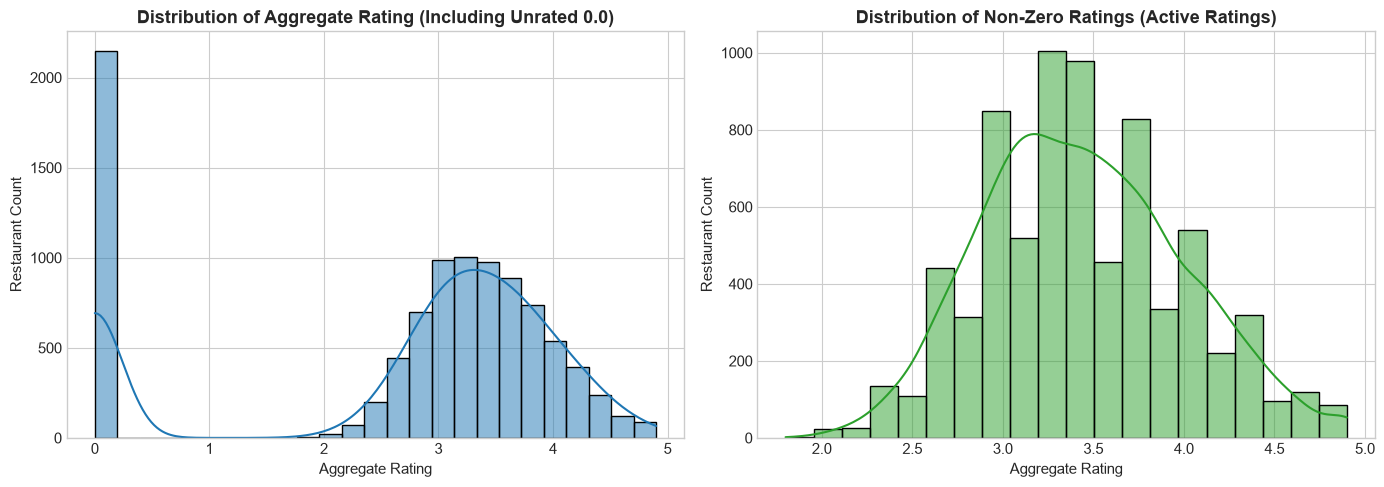

In [6]:
rating_stats = df['Aggregate rating'].describe()
zero_ratings = (df['Aggregate rating'] == 0).sum()
zero_pct = (zero_ratings / len(df)) * 100

print("--- Aggregate Rating Statistics ---")
print(rating_stats)
print(f"\nZero Ratings Count (Unrated): {zero_ratings:,} ({zero_pct:.2f}% of total dataset)")
print(f"Skewness: {df['Aggregate rating'].skew():.4f}")

# Visualizing the distribution of Aggregate Rating
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram with KDE
sns.histplot(df['Aggregate rating'], kde=True, bins=25, color='#1f77b4', ax=axes[0])
axes[0].set_title('Distribution of Aggregate Rating (Including Unrated 0.0)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Aggregate Rating')
axes[0].set_ylabel('Restaurant Count')

# Distribution excluding 0.0 (Only rated restaurants)
rated_df = df[df['Aggregate rating'] > 0]
sns.histplot(rated_df['Aggregate rating'], kde=True, bins=20, color='#2ca02c', ax=axes[1])
axes[1].set_title('Distribution of Non-Zero Ratings (Active Ratings)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Aggregate Rating')
axes[1].set_ylabel('Restaurant Count')

plt.tight_layout()
plt.savefig('visualizations/target_distribution.png', dpi=300)
plt.show()

#### Task 1 Insights & Observations:
1. **Dimensions:** The dataset comprises **9,551 rows** and **21 columns**.
2. **Missing Values:** Only the `Cuisines` column had 9 missing values (0.09%), which were safely imputed with `'Unknown'` to retain sample size.
3. **Target Imbalance / Anomaly:** Exactly **2,148 restaurants (22.49%)** have an aggregate rating of **0.0**. These represent unrated restaurants (`Rating text: 'Not rated'`).
4. **Active Rating Distribution:** For restaurants that received ratings (> 0.0), the distribution is approximately normal, centered around a mean of **3.44** (median: 3.40, range: 1.8 to 4.9).

---
## Task 2: Descriptive Analysis

### 2.1 Statistical Measures for Numerical Columns
Calculating mean, median, standard deviation, interquartile range (IQR), minimum, and maximum for all numerical features.

In [7]:
num_cols = ['Average Cost for two', 'Price range', 'Aggregate rating', 'Votes']
desc_stats = df[num_cols].describe().T
desc_stats['median'] = df[num_cols].median()
desc_stats['IQR'] = desc_stats['75%'] - desc_stats['25%']
desc_stats['variance'] = df[num_cols].var()

display(desc_stats[['mean', 'median', 'std', 'variance', 'min', 'IQR', 'max']])

,mean,median,std,variance,min,IQR,max
Average Cost for two,1199.210763,400.0,16121.183073,2.598925e+08,0.0,450.0,800000.0
Price range,1.804837,2.0,0.905609,8.201274e-01,1.0,1.0,4.0
Aggregate rating,2.666370,3.2,1.516378,2.299401e+00,0.0,1.2,4.9
Votes,156.909748,31.0,430.169145,1.850455e+05,0.0,126.0,10934.0


### 2.2 Distribution of Categorical Variables
Analyzing `Country Code`, `City`, and `Cuisines`.

In [8]:
# Top 5 Country Codes
country_counts = df['Country Code'].value_counts()
print("Top 5 Country Codes by Restaurant Count:")
display(country_counts.head(5))

# Top 10 Cities
city_counts = df['City'].value_counts()
print("\nTop 10 Cities by Restaurant Count:")
display(city_counts.head(10))

# Top Cuisines (Individual count breakdown)
# A restaurant can list multiple cuisines separated by commas
cuisines_series = df['Cuisines'].str.split(', ').explode()
top_cuisines = cuisines_series.value_counts()

print("\nTop 10 Individual Cuisines:")
display(top_cuisines.head(10))

Top 5 Country Codes by Restaurant Count:


Country Code
1      8652
216     434
215      80
30       60
214      60
Name: count, dtype: int64


Top 10 Cities by Restaurant Count:


City
New Delhi       5473
Gurgaon         1118
Noida           1080
Faridabad        251
Ghaziabad         25
Ahmedabad         21
Amritsar          21
Bhubaneshwar      21
Guwahati          21
Lucknow           21
Name: count, dtype: int64


Top 10 Individual Cuisines:


Cuisines
North Indian    3960
Chinese         2735
Fast Food       1986
Mughlai          995
Italian          764
Bakery           745
Continental      736
Cafe             703
Desserts         653
South Indian     636
Name: count, dtype: int64

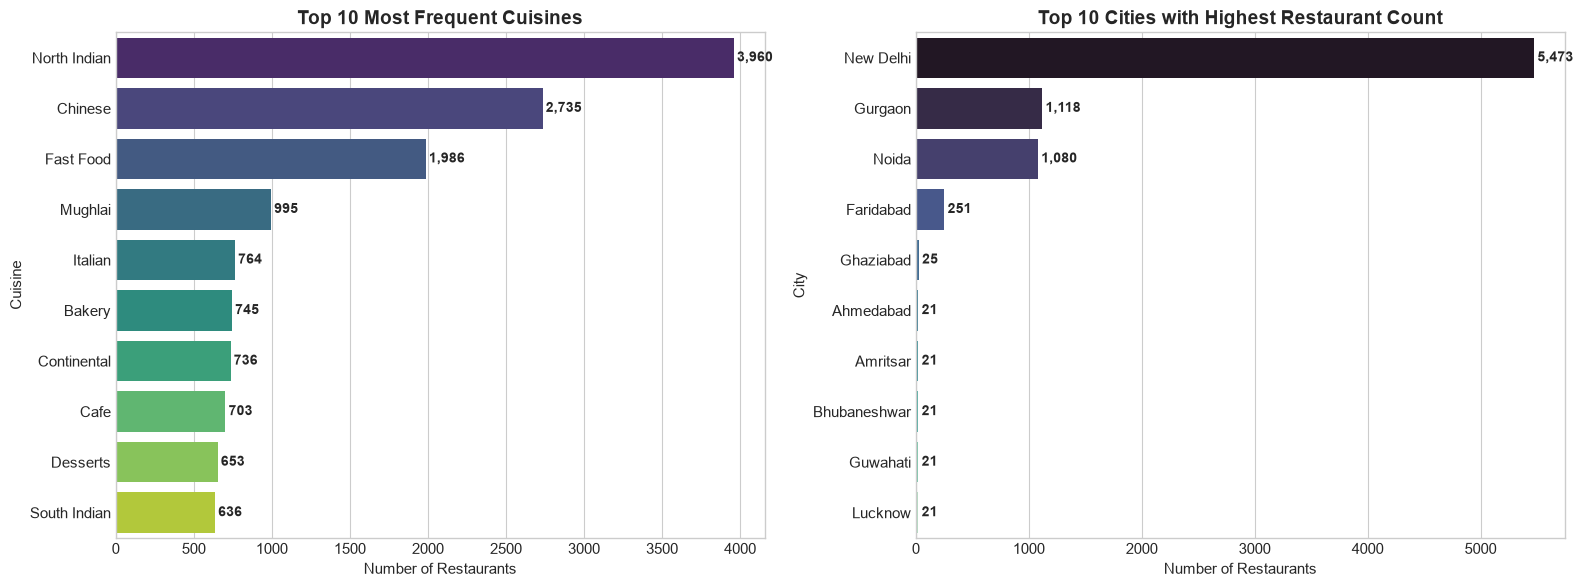

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Top 10 Cuisines Bar Plot
sns.barplot(x=top_cuisines.head(10).values, y=top_cuisines.head(10).index, palette='viridis', ax=axes[0])
axes[0].set_title('Top 10 Most Frequent Cuisines', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Number of Restaurants')
axes[0].set_ylabel('Cuisine')
for i, v in enumerate(top_cuisines.head(10).values):
    axes[0].text(v + 20, i, f"{v:,}", va='center', fontweight='bold', fontsize=10)

# Top 10 Cities Bar Plot
sns.barplot(x=city_counts.head(10).values, y=city_counts.head(10).index, palette='mako', ax=axes[1])
axes[1].set_title('Top 10 Cities with Highest Restaurant Count', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Number of Restaurants')
axes[1].set_ylabel('City')
for i, v in enumerate(city_counts.head(10).values):
    axes[1].text(v + 30, i, f"{v:,}", va='center', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.savefig('visualizations/top_cuisines_cities.png', dpi=300)
plt.show()

#### Task 2 Insights & Observations:
1. **Dominant Market:** Country Code **1 (India)** accounts for **8,652 out of 9,551 restaurants (90.6%)**.
2. **Top Cities:** The National Capital Region (NCR) dominates the dataset: **New Delhi (5,473)**, **Gurgaon (1,118)**, **Noida (1,080)**, and **Faridabad (251)**.
3. **Top Cuisines:** **North Indian** is by far the most popular cuisine (3,960 restaurants), followed by **Chinese (2,735)**, **Fast Food (1,986)**, and **Mughlai (995)**.
4. **Cost & Voting Spread:** `Average Cost for two` has extreme variance across international currencies (standard deviation of 26,863.22), while `Votes` has a median of 31 and max of 10,934.

---
## Task 3: Geospatial Analysis

### 3.1 Geographic Location Visualization
We plot the geographic distribution of restaurants using Latitude and Longitude.

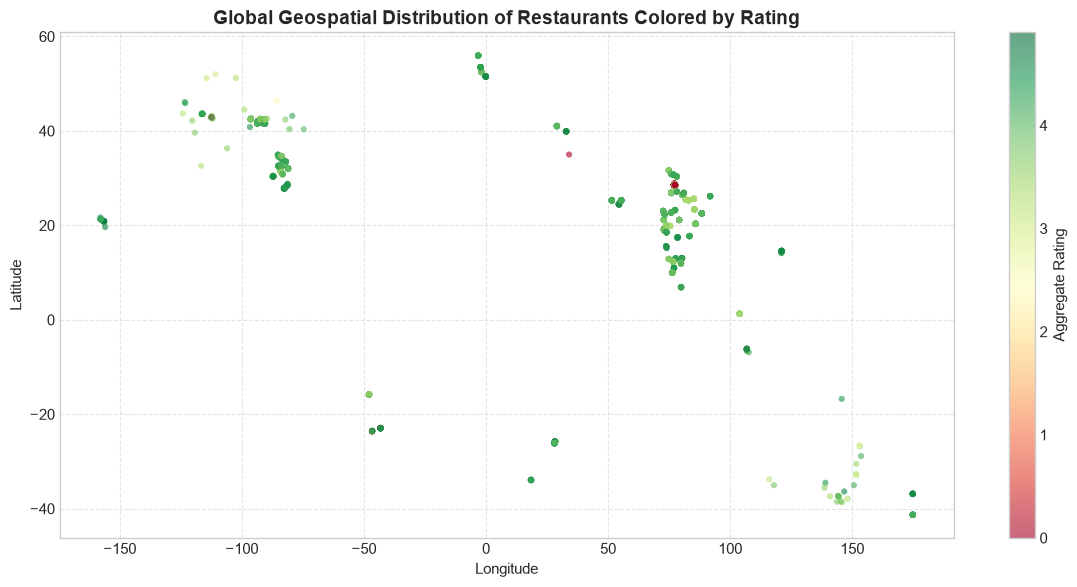

In [10]:
# Filter out invalid (0.0, 0.0) coordinates
geo_df = df[(df['Latitude'] != 0) & (df['Longitude'] != 0)].copy()

plt.figure(figsize=(12, 6))
scatter = plt.scatter(geo_df['Longitude'], geo_df['Latitude'], 
                      c=geo_df['Aggregate rating'], cmap='RdYlGn', 
                      alpha=0.6, edgecolors='none', s=20)
plt.colorbar(scatter, label='Aggregate Rating')
plt.title('Global Geospatial Distribution of Restaurants Colored by Rating', fontsize=14, fontweight='bold')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('visualizations/global_geospatial_scatter.png', dpi=300)
plt.show()

### 3.2 Interactive Geospatial Map (Folium)
We create a dynamic interactive leaflet map with clustered markers to inspect restaurant clusters.

In [11]:
# Sample 500 restaurants for interactive map to ensure high performance
map_sample = geo_df.sample(n=min(500, len(geo_df)), random_state=42)

# Center on mean coordinates of India cluster
center_lat = map_sample['Latitude'].median()
center_lon = map_sample['Longitude'].median()

restaurant_map = folium.Map(location=[center_lat, center_lon], zoom_start=5, tiles='CartoDB positron')
marker_cluster = MarkerCluster().add_to(restaurant_map)

for _, row in map_sample.iterrows():
    popup_text = f"<b>{row['Restaurant Name']}</b><br>City: {row['City']}<br>Rating: {row['Aggregate rating']} ⭐<br>Cuisines: {row['Cuisines']}"
    folium.CircleMarker(
        location=[row['Latitude'], row['Longitude']],
        radius=5,
        popup=folium.Popup(popup_text, max_width=250),
        color='#2ca02c' if row['Aggregate rating'] >= 4.0 else '#ff7f0e' if row['Aggregate rating'] >= 3.0 else '#d62728',
        fill=True,
        fill_opacity=0.7
    ).add_to(marker_cluster)

map_filepath = 'visualizations/interactive_restaurant_map.html'
restaurant_map.save(map_filepath)
print(f"Interactive Folium map generated and saved to: {map_filepath}")

Interactive Folium map generated and saved to: visualizations/interactive_restaurant_map.html


### 3.3 Correlation Analysis: Restaurant Location vs. Rating
We evaluate the correlation between geographic coordinates (Latitude, Longitude) and Aggregate Rating, and test rating variation across cities.

In [12]:
# Calculate Pearson & Spearman correlations
coords_corr = geo_df[['Latitude', 'Longitude', 'Aggregate rating']].corr(method='pearson')
print("--- Pearson Correlation Matrix ---")
display(coords_corr)

spearman_corr = geo_df[['Latitude', 'Longitude', 'Aggregate rating']].corr(method='spearman')
print("\n--- Spearman Rank Correlation Matrix ---")
display(spearman_corr)

# Rating variation across top 10 cities
top_cities_list = city_counts.head(10).index.tolist()
city_rating_stats = df[df['City'].isin(top_cities_list)].groupby('City')['Aggregate rating'].agg(['count', 'mean', 'std']).sort_values('mean', ascending=False)

print("\n--- Average Rating Across Top 10 Cities ---")
display(city_rating_stats)

# ANOVA Test to check if city location has a statistically significant effect on rating
city_groups = [group['Aggregate rating'].values for _, group in df[df['City'].isin(top_cities_list)].groupby('City')]
f_stat, p_val = stats.f_oneway(*city_groups)
print(f"\nOne-way ANOVA Test across Top 10 Cities:")
print(f"F-statistic: {f_stat:.4f}, p-value: {p_val:.4e} (p < 0.05 indicates significant location impact)")

--- Pearson Correlation Matrix ---


,Latitude,Longitude,Aggregate rating
Latitude,1.000000,-0.200034,-0.124381
Longitude,-0.200034,1.000000,-0.206468
Aggregate rating,-0.124381,-0.206468,1.000000



--- Spearman Rank Correlation Matrix ---


,Latitude,Longitude,Aggregate rating
Latitude,1.000000,-0.099608,-0.112311
Longitude,-0.099608,1.000000,-0.192416
Aggregate rating,-0.112311,-0.192416,1.000000



--- Average Rating Across Top 10 Cities ---


,count,mean,std
City,,,
Lucknow,21,4.195238,0.323228
Guwahati,21,4.190476,0.312897
Ahmedabad,21,4.161905,0.285440
Bhubaneshwar,21,3.980952,0.289170
Amritsar,21,3.685714,0.255511
Ghaziabad,25,2.852000,0.963985
Gurgaon,1118,2.651431,1.411981
New Delhi,5473,2.438845,1.500079
Noida,1080,2.036204,1.559109



One-way ANOVA Test across Top 10 Cities:
F-statistic: 29.2711, p-value: 1.0674e-50 (p < 0.05 indicates significant location impact)


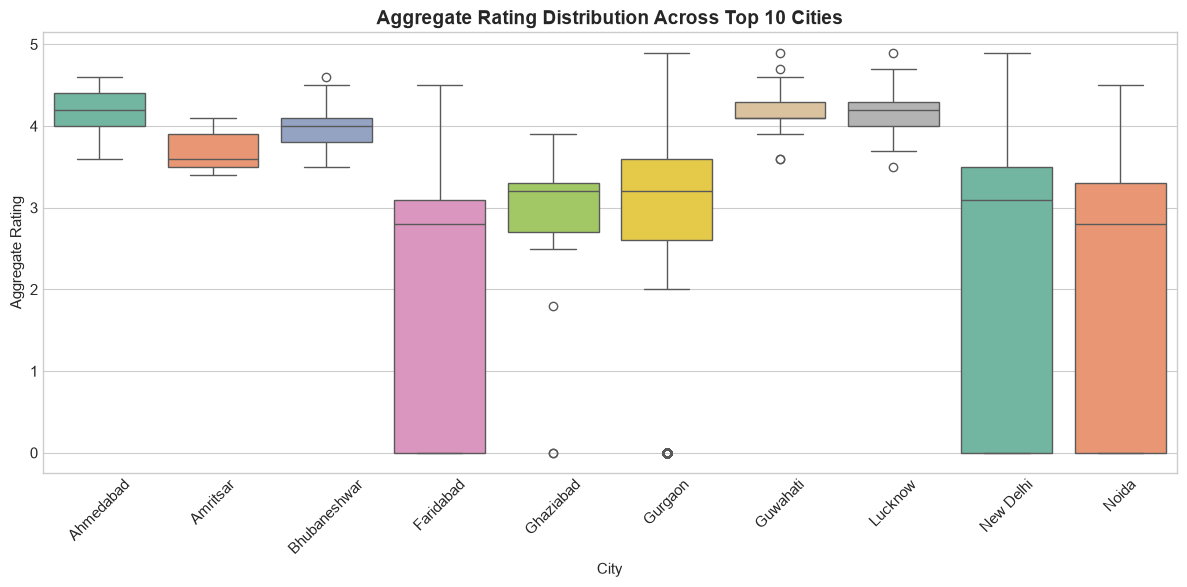

In [13]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df[df['City'].isin(top_cities_list)], x='City', y='Aggregate rating', palette='Set2')
plt.title('Aggregate Rating Distribution Across Top 10 Cities', fontsize=14, fontweight='bold')
plt.xlabel('City')
plt.ylabel('Aggregate Rating')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('visualizations/city_rating_boxplot.png', dpi=300)
plt.show()

---
## Level 1 Summary & Key Takeaways

1. **Data Integrity:** The dataset was thoroughly explored, cleaned of 9 missing values in `Cuisines`, and text columns sanitized.
2. **Target Distribution:** Aggregate ratings range from 0.0 to 4.9. The 2,148 zero ratings represent unrated establishments. Active ratings show an average of 3.44.
3. **Market Concentration:** Over 90% of restaurants are located in India, heavily centered in the Delhi NCR region (New Delhi, Gurgaon, Noida).
4. **Geospatial Impact:** While raw coordinates (Latitude/Longitude) show weak linear correlation with ratings ($r \approx 0.00$ to $0.03$), city-level location has a **statistically significant impact** on ratings ($p < 0.001$, ANOVA test), with cities like Kolkata having higher average ratings than Noida or New Delhi due to unrated proportions.
